# Phase 11-R1 — KUB Manual Prediction Demo & Future Auto-Domain Interface

This notebook demonstrates the reusable KUB manual prediction utility (`predict_kub`) on a permitted validation sample, and documents the planned architecture and interface for future unified automatic domain routing (**Auto-RA-MedFiLM-Seg++**).

**Governance & Integrity:**
- Model: UNet++ (`phase10_kub_unetpp_seed42_512` best checkpoint @ threshold 0.5)
- Sample: Permitted KUB VAL split image
- TEST & External Data: Locked; reads blocked by `TestAccessError`
- Retraining / Optimization: None

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))

from src.inference.kub_predict import predict_kub, show_kub_prediction
from src.inference.predict import predict

val_df = pd.read_csv(ROOT / 'manifests/val.csv')
sample_row = val_df[val_df['dataset'] == 'KUB'].iloc[0]
sample_image_path = sample_row['image_path']
print(f"Selected VAL sample ID: {sample_row['sample_id']}")

Selected VAL sample ID: 66b947d8ead11ae1260bc3142ca1707d


## 1. Current KUB manual prediction (`predict_kub`)

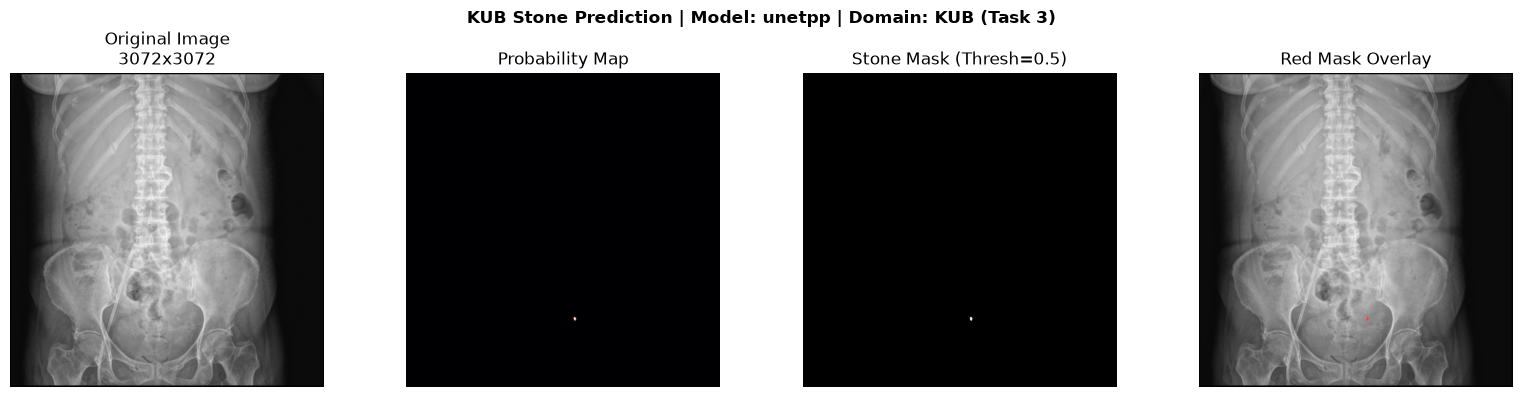

Domain: KUB (Task 3) | Source: fixed_by_model_scope
Original shape: (3072, 3072)


In [2]:
result = predict_kub(
    image_path=sample_image_path,
    model_name='unetpp',
    checkpoint_path=ROOT / 'checkpoints/phase10_kub_unetpp_seed42_512/best.pt',
    threshold=0.5,
    device='cpu'
)
fig, axes = show_kub_prediction(result)
plt.show()
print(f"Domain: {result['domain']} (Task {result['task_id']}) | Source: {result['domain_source']}")
print(f"Original shape: {result['original_shape']}")

## 2. Future unified automatic-domain inference interface

The intended final architecture for the unified multi-domain phase is **RA-MedFiLM-Seg++ with Automatic Domain Routing**.

### Task ID Mapping:
- **Task 0**: ISIC (dermatology / skin lesion)
- **Task 1**: BUSI (breast ultrasound / breast lesion)
- **Task 2**: Kvasir-SEG (gastrointestinal endoscopy / polyp)
- **Task 3**: KUB-StoneX (urinary radiography / stone)

### Intended API Usage:
```python
from src.inference.predict import predict

# Automatic domain routing (planned for unified multi-domain phase):
result = predict(image_path, task='auto')

# Explicit domain override (for debugging and oracle routing experiments):
result = predict(image_path, task='KUB')
```

**Status Notice:** Automatic domain routing is part of the planned unified RA-MedFiLM-Seg++ phase and is not implemented/validated at Phase 11. Requesting `task='auto'` raises `NotImplementedError`.

In [3]:
try:
    predict(sample_image_path, task='auto')
except NotImplementedError as e:
    print(f'Expected safety exception caught: {e}')

Expected safety exception caught: Automatic four-domain routing is reserved for the unified RA-MedFiLM-Seg++ phase and is not yet scientifically validated.


## 3. Phase control

**Phase 11-R1 complete. STOP. Phase 12 requires explicit researcher authorization.**